# SymPyLab - Laboratorio 4: Polinomios en Wolfram Alpha y SymPy
**Métodos Numéricos (2026-II) - Universidad Nacional de Colombia**

- **Estudiante:** Juan Manuel Cristancho Alvarez
- **Usuario UNAL:** `jcristanchoa`
- **Correo Institucional:** `jcristanchoa@unal.edu.co`
- **Usuario GitHub:** `SajoOP`
- **Repositorio:** `MetNumUN2026II / Lab4`
- **Número de Lista:** **16**
- **Raíz Base Asignada ($16 \pmod{10}$):** $\mathbf{6}$

---
### Documentación Oficial y Recursos:
- [SymPy Documentation](https://docs.sympy.org/latest/index.html)
- [SymPy Polynomials Basics](https://docs.sympy.org/latest/modules/polys/basics.html#polynomials)
- [SymPy Solvers Tutorial](https://docs.sympy.org/latest/tutorial/solvers.html)
- [SymPy Poly Domains Reference](https://docs.sympy.org/dev/modules/polys/domainsref.html)
- [Wolfram Alpha Computational Intelligence](https://www.wolframalpha.com/)


## SymPy’s polynomials
- https://docs.sympy.org/latest/modules/polys/basics.html#polynomials

$$ P_n(x) =  a_n x^n + a_{n-1} x^{n-1} + a_{n-2} x^{n-2} +\cdots +  a_1 x  + a_0$$

$$P_n(x) = 0 $$

$$a_n x^n + a_{n-1} x^{n-1} + a_{n-2} x^{n-2} +\cdots +  a_1 x  + a_0 = 0$$

Por el **Teorema del Factor** y el **Teorema Fundamental del Álgebra**, si $r_1$ es una raíz de $P_n(x)$, entonces $(x - r_1)$ divide exactamente a $P_n(x)$:

$$(x-r_1) Q_{n-1}(x) = P_n(x) \implies P_n(r_1) = 0$$

Factorizando sucesivamente las $n$ raíces (reales y complejas):

$$(x-r_1)(x-r_2) Q_{n-2}(x) = P_n(x) \implies P_n(r_2) = 0$$

$$a_n (x-r_1)(x-r_2)\cdots (x-r_n) = P_n(x)$$


# Number of operations to compute a polynomial

Analizamos la complejidad algorítmica y el costo computacional (número de operaciones elementales) requeridas para evaluar un polinomio de grado $n$ en un punto $x$ según su representación algebraica.

---
## 1. Extended Form (Forma Extendida)
$$ P_n(x) = a_n x^n + a_{n-1} x^{n-1} + a_{n-2} x^{n-2} + \cdots + a_2 x^2 + a_1 x + a_0$$

Calculando cada potencia de forma ingenua ($x^k = x \cdot x \cdots x$ con $k-1$ multiplicaciones) y luego multiplicando por $a_k$:
- Multiplicaciones para calcular los términos: $n + (n-1) + \cdots + 2 + 1 = \sum_{i=1}^n i = \frac{n(n+1)}{2} \text{ (*)}$
- Sumas para acumular los términos: $n \text{ (+)}$
- **Total de operaciones:**
$$\frac{n(n+1)}{2} (*) + n (+) = \frac{n^2 + 3n}{2} \text{ ops}$$

*Para un polinomio de grado $n = 5$:*
$$\frac{5 \cdot 6}{2} (*) + 5 (+) = 15 (*) + 5 (+) = 20 \text{ ops}$$

*Para nuestro polinomio de grado $n = 10$:*
$$\frac{10 \cdot 11}{2} (*) + 10 (+) = 55 (*) + 10 (+) = \mathbf{65 \text{ ops}}$$

---
## 2. Monomials Product Form (Producto de Monomios)
$$ P_n(x) = a_n (x-r_1)(x-r_2)(x-r_3)\cdots (x-r_n)$$

Suponiendo $a_n = 1$ (polinomio mónico):
- Restas dentro de cada monomio $(x - r_i)$: $n \text{ (-)}$
- Multiplicaciones entre los $n$ binomios: $(n-1) \text{ (*)}$
- **Total de operaciones:**
$$(n-1) (*) + n (-) = 2n - 1 \text{ ops}$$

*Para un polinomio de grado $n = 5$:*
$$4 (*) + 5 (-) = 9 \text{ ops}$$

*Para nuestro polinomio de grado $n = 10$:*
$$9 (*) + 10 (-) = \mathbf{19 \text{ ops}}$$

---
## 3. Nested Form / Horner's Method (Forma Anidada / Método de Horner)
$$ P_n(x) = (((((a_n x + a_{n-1})x + a_{n-2})x + \cdots + a_2)x + a_1)x + a_0 $$

El algoritmo de Horner factoriza $x$ repetidamente, reduciendo drásticamente la cantidad de multiplicaciones:
- Multiplicaciones por $x$: $n \text{ (*)}$
- Sumas de los coeficientes $a_i$: $n \text{ (+)}$
- **Total de operaciones:**
$$n (*) + n (+) = 2n \text{ ops}$$

*Para un polinomio de grado $n = 5$:*
$$5 (*) + 5 (+) = 10 \text{ ops}$$

*Para nuestro polinomio de grado $n = 10$:*
$$10 (*) + 10 (+) = \mathbf{20 \text{ ops}}$$

---
### Tabla Comparativa de Complejidad ($n = 10$)
| Representación | Multiplicaciones | Sumas / Restas | Total Operaciones | Complejidad Asintótica |
| :--- | :---: | :---: | :---: | :---: |
| **Extended Form** | 55 | 10 | **65 ops** | $\mathcal{O}(n^2)$ |
| **Monomials Product** | 9 | 10 | **19 ops** | $\mathcal{O}(n)$ |
| **Nested (Horner)** | 10 | 10 | **20 ops** | $\mathcal{O}(n)$ |


### Ejemplo Base del Profesor (Grado 5)
$$P(x) = (x-1)(x-2)(x-3)(x-4)(x-5) = x^5 - 15x^4 + 85x^3 - 225x^2 + 274x - 120$$

<img src="https://raw.githubusercontent.com/gjhernandezp/NM/main/SymPyLab/sympylabwolfram1.jpg" width="48%" /> <img src="https://raw.githubusercontent.com/gjhernandezp/NM/main/SymPyLab/sympylabwolfram2.jpg" width="48%" />


# **My own example 1**

### Definición del Polinomio de Grado 10
- **Número de lista:** $16$
- **Raíz obligatoria ($16 \pmod{10}$):** $r_1 = \mathbf{6}$
- **Otras raíces enteras y racionales elegidas:**
  $$r_2 = 1, \quad r_3 = 2, \quad r_4 = 3, \quad r_5 = 4, \quad r_6 = 5, \quad r_7 = -1, \quad r_8 = -2, \quad r_9 = \frac{1}{2}, \quad r_{10} = -\frac{1}{2}$$

### 1. Forma de Producto de Monomios:
$$P_{10}(x) = (x - 6)(x - 1)(x - 2)(x - 3)(x - 4)(x - 5)(x + 1)(x + 2)\left(x - \frac{1}{2}\right)\left(x + \frac{1}{2}\right)$$

### 2. Forma Extendida (Expandida con SymPy):
$$P_{10}(x) = x^{10} - 18x^9 + \frac{455}{4}x^8 - \frac{495}{2}x^7 - \frac{519}{2}x^6 + 1701x^5 - \frac{5065}{4}x^4 - \frac{3555}{2}x^3 + 1771x^2 + 342x - 360$$

### 3. Forma Anidada (Horner):
$$P_{10}(x) = (((((((((x - 18)x + 113.75)x - 247.5)x - 259.5)x + 1701)x - 1266.25)x - 1777.5)x + 1771)x + 342)x - 360$$

### 4. Conteo de Operaciones para $n = 10$:
- **Extended Form:**
  $$\frac{10 \cdot 11}{2} (*) + 10 (+) = 55 (*) + 10 (+) = \mathbf{65 \text{ operaciones}}$$
- **Monomials Product Form:**
  $$9 (*) + 10 (-) = \mathbf{19 \text{ operaciones}}$$
- **Nested Form (Horner):**
  $$10 (*) + 10 (+) = \mathbf{20 \text{ operaciones}}$$

---
### Consulta en Wolfram Alpha:
- **Enlace de consulta directa en Wolfram Alpha:**  
  [Wolfram Alpha: Expand (x-6)(x-1)(x-2)(x-3)(x-4)(x-5)(x+1)(x+2)(x-1/2)(x+1/2)](https://www.wolframalpha.com/input?i=expand+%28x-6%29%28x-1%29%28x-2%29%28x-3%29%28x-4%29%28x-5%29%28x%2B1%29%28x%2B2%29%28x-1%2F2%29%28x%2B1%2F2%29)


MY OWN EXAMPLE 1: POLINOMIO DE GRADO 10
1. Producto de monomios P(x):
(x - 6)*(x - 5)*(x - 4)*(x - 3)*(x - 2)*(x - 1)*(x - 1/2)*(x + 1/2)*(x + 1)*(x + 2)

2. Forma extendida P(x):
x**10 - 18*x**9 + 455*x**8/4 - 495*x**7/2 - 519*x**6/2 + 1701*x**5 - 5065*x**4/4 - 3555*x**3/2 + 1771*x**2 + 342*x - 360

3. Forma anidada de Horner P(x):
x*(x*(x*(x*(x*(x*(x*(x*(x*(x - 18) + 455/4) - 495/2) - 519/2) + 1701) - 5065/4) - 3555/2) + 1771) + 342) - 360

4. Conteo de operaciones para grado n = 10
   - Forma Extendida : 55 (*) + 10 (+) = 65 ops
   - Prod. Monomios  : 9 (*) + 10 (-) = 19 ops
   - Forma de Horner : 10 (*) + 10 (+) = 20 ops


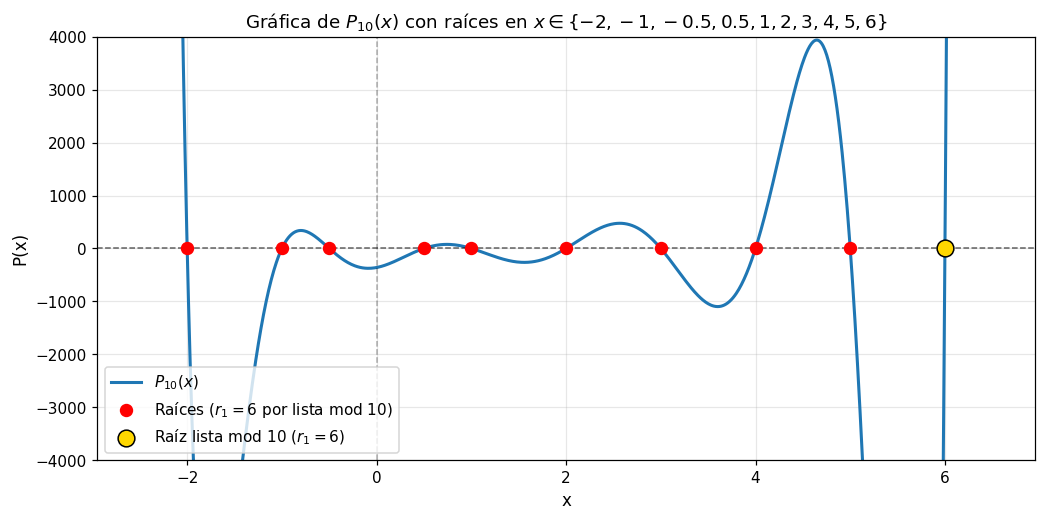

In [1]:
from sympy import Symbol, expand, Rational, horner
import numpy as np
import matplotlib.pyplot as plt

x = Symbol('x')

# Definir raíces con r1 = 16 % 10 = 6
roots = [6, 1, 2, 3, 4, 5, -1, -2, Rational(1, 2), Rational(-1, 2)]

# Construcción como producto de monomios
P = 1
for r in roots:
    P *= (x - r)

print("="*70)
print("MY OWN EXAMPLE 1: POLINOMIO DE GRADO 10")
print("="*70)
print("1. Producto de monomios P(x):")
print(P)

# Forma extendida
P_expanded = expand(P)
print("\n2. Forma extendida P(x):")
print(P_expanded)

# Forma anidada de Horner
P_horner = horner(P_expanded)
print("\n3. Forma anidada de Horner P(x):")
print(P_horner)

# Operaciones
n = len(roots)
ops_ext = (n * (n + 1)) // 2 + n
ops_prod = (n - 1) + n
ops_horner = n + n
print("\n4. Conteo de operaciones para grado n =", n)
print(f"   - Forma Extendida : {n*(n+1)//2} (*) + {n} (+) = {ops_ext} ops")
print(f"   - Prod. Monomios  : {n-1} (*) + {n} (-) = {ops_prod} ops")
print(f"   - Forma de Horner : {n} (*) + {n} (+) = {ops_horner} ops")

# Gráfica del polinomio con las raíces marcadas
x_vals = np.linspace(-2.5, 6.5, 1000)
def eval_p(val):
    return (val - 6)*(val - 1)*(val - 2)*(val - 3)*(val - 4)*(val - 5)*(val + 1)*(val + 2)*(val - 0.5)*(val + 0.5)

y_vals = eval_p(x_vals)

plt.figure(figsize=(11, 5))
plt.plot(x_vals, y_vals, label=r'$P_{10}(x)$', color='#1f77b4', lw=2)
plt.axhline(0, color='black', linestyle='--', alpha=0.6, lw=1)
plt.axvline(0, color='black', linestyle='--', alpha=0.3, lw=1)

# Graficar raíces
roots_float = [float(r) for r in roots]
plt.scatter(roots_float, [0]*len(roots_float), color='red', s=60, zorder=5, 
            label=f'Raíces ($r_1=6$ por lista mod 10)')

# Destacar raíz r1 = 6
plt.scatter([6], [0], color='gold', edgecolor='black', s=120, zorder=6, label=r'Raíz lista mod 10 ($r_1=6$)')

plt.title(r'Gráfica de $P_{10}(x)$ con raíces en $x \in \{-2, -1, -0.5, 0.5, 1, 2, 3, 4, 5, 6\}$', fontsize=12)
plt.xlabel('x', fontsize=11)
plt.ylabel('P(x)', fontsize=11)
plt.ylim(-4000, 4000)
plt.grid(True, alpha=0.3)
plt.legend(loc='lower left', frameon=True)
plt.show()


# **My own example 2**

### División en Wolfram Alpha y SymPy por un monomio que NO es parte del producto

Tomamos nuestro polinomio de grado 10 $P_{10}(x)$ y lo dividimos por un monomio que **NO** forme parte del producto original:
$$(x - 7)$$
*(Nótese que $7$ no pertenece al conjunto de raíces $\{-2, -1, -1/2, 1/2, 1, 2, 3, 4, 5, 6\}$).*

Por el **Teorema del Resto (Remainder Theorem)**, el residuo $R$ de dividir $P_{10}(x)$ entre $(x - 7)$ es exactamente el valor numérico $P_{10}(7)$:
$$R = P_{10}(7) = (7-6)(7-1)(7-2)(7-3)(7-4)(7-5)(7+1)(7+2)\left(7^2 - \frac{1}{4}\right)$$
$$R = (1)(6)(5)(4)(3)(2)(8)(9)(48.75) = 720 \cdot 72 \cdot 48.75 = \mathbf{2\,527\,200}$$

La división arroja:
$$\frac{P_{10}(x)}{x - 7} = Q_9(x) + \frac{R}{x - 7}$$

Donde el cociente es de grado 9:
$$Q_9(x) = x^9 - 11x^8 + \frac{147}{4}x^7 + \frac{39}{4}x^6 - \frac{765}{4}x^5 + \frac{1449}{4}x^4 + \frac{2539}{2}x^3 + 7109x^2 + 51534x + 361080$$
Y el residuo no nulo es:
$$R = \mathbf{2\,527\,200}$$

---
### Consulta en Wolfram Alpha:
- **Enlace de consulta directa en Wolfram Alpha:**  
  [Wolfram Alpha: ((x-6)(x-1)(x-2)(x-3)(x-4)(x-5)(x+1)(x+2)(x-1/2)(x+1/2)) / (x-7)](https://www.wolframalpha.com/input?i=%28%28x-6%29%28x-1%29%28x-2%29%28x-3%29%28x-4%29%28x-5%29%28x%2B1%29%28x%2B2%29%28x-1%2F2%29%28x%2B1%2F2%29%29+%2F+%28x-7%29)


MY OWN EXAMPLE 2: DIVISIÓN POR MONOMIO NO PERTENECIENTE AL PRODUCTO
Polinomio dividendo P(x):
x**10 - 18*x**9 + 455*x**8/4 - 495*x**7/2 - 519*x**6/2 + 1701*x**5 - 5065*x**4/4 - 3555*x**3/2 + 1771*x**2 + 342*x - 360

Monomio divisor:
x - 7

Cociente Q(x) (grado 9):
x**9 - 11*x**8 + 147*x**7/4 + 39*x**6/4 - 765*x**5/4 + 1449*x**4/4 + 2539*x**3/2 + 7109*x**2 + 51534*x + 361080

Residuo R:
2527200

Verificación por Teorema del Resto P(7): 2527200
>> VERIFICACIÓN EXITOSA: R == P(7) != 0


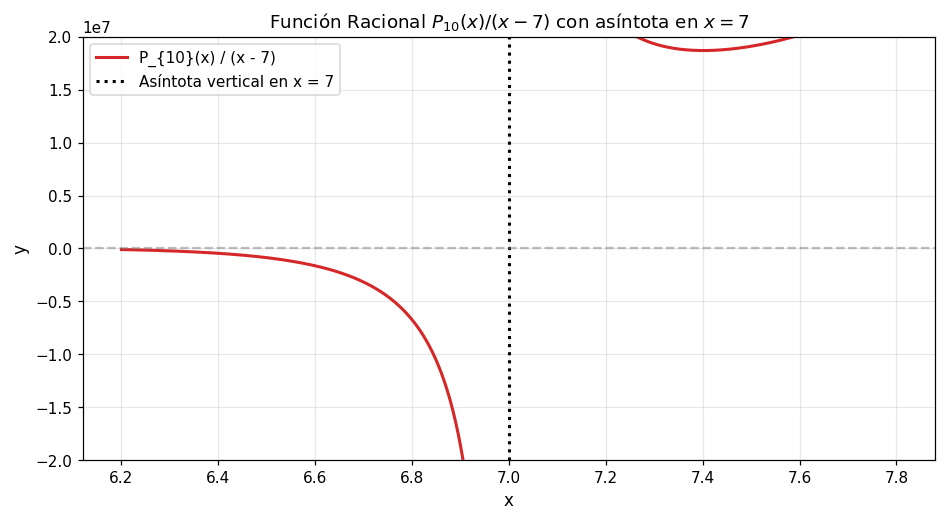

In [2]:
from sympy import Symbol, div, Rational, expand
import numpy as np
import matplotlib.pyplot as plt

x = Symbol('x')

# Definición del polinomio P10(x)
roots = [6, 1, 2, 3, 4, 5, -1, -2, Rational(1, 2), Rational(-1, 2)]
p = 1
for r in roots:
    p *= (x - r)
p = expand(p)

# Monomio NO perteneciente al producto: (x - 7)
divisor = x - 7

# División polinomial con div de SymPy
q, r = div(p, divisor)

print("="*70)
print("MY OWN EXAMPLE 2: DIVISIÓN POR MONOMIO NO PERTENECIENTE AL PRODUCTO")
print("="*70)
print("Polinomio dividendo P(x):")
print(p)
print("\nMonomio divisor:")
print(divisor)
print("\nCociente Q(x) (grado 9):")
print(q)
print("\nResiduo R:")
print(r)

# Verificación con el Teorema del Resto
r_teorema = p.subs(x, 7)
print(f"\nVerificación por Teorema del Resto P(7): {r_teorema}")
assert r == r_teorema, "Error: el residuo debe coincidir con P(7)"
print(">> VERIFICACIÓN EXITOSA: R == P(7) != 0")

# Gráfica de la función racional P(x)/(x - 7)
x_plot = np.linspace(6.2, 7.8, 1000)
x_left = x_plot[x_plot < 6.98]
x_right = x_plot[x_plot > 7.02]

def eval_rational(v):
    P_val = (v - 6)*(v - 1)*(v - 2)*(v - 3)*(v - 4)*(v - 5)*(v + 1)*(v + 2)*(v**2 - 0.25)
    return P_val / (v - 7)

plt.figure(figsize=(10, 5))
plt.plot(x_left, eval_rational(x_left), color='#d62728', lw=2, label=r'P_{10}(x) / (x - 7)')
plt.plot(x_right, eval_rational(x_right), color='#d62728', lw=2)
plt.axvline(7, color='black', linestyle=':', lw=2, label='Asíntota vertical en x = 7')
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)

plt.title(r'Función Racional $P_{10}(x) / (x - 7)$ con asíntota en $x = 7$', fontsize=12)
plt.xlabel('x', fontsize=11)
plt.ylabel('y', fontsize=11)
plt.ylim(-2e7, 2e7)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.show()


# **My own example 3**

### División Sucesiva por Cada Uno de los Monomios del Producto

Dividimos sucesivamente el polinomio $P_{10}(x)$ entre cada uno de los 10 factores que lo componen:
$$(x - 6), \quad (x - 1), \quad (x - 2), \quad (x - 3), \quad (x - 4), \quad (x - 5), \quad (x + 1), \quad (x + 2), \quad \left(x - \frac{1}{2}\right), \quad \left(x + \frac{1}{2}\right)$$

En cada iteración $k$:
$$P_{10 - (k-1)}(x) = (x - r_k) Q_{10 - k}(x) + R_k$$

Como cada $(x - r_k)$ es un factor exacto:
- El residuo en cada paso es estrictamente **$R_k = 0$**.
- El grado del cociente resultante disminuye exactamente en 1 unidad en cada paso ($10 \to 9 \to 8 \to \dots \to 1 \to 0$).
- Tras dividir por los 10 factores, el cociente final es exactamente el coeficiente principal: **$1$**.


In [3]:
from sympy import Symbol, div, Rational, expand

x = Symbol('x')

# Definir polinomio y sus factores mónicos
roots = [6, 1, 2, 3, 4, 5, -1, -2, Rational(1, 2), Rational(-1, 2)]
p = 1
for r in roots:
    p *= (x - r)
p = expand(p)

print("="*70)
print("MY OWN EXAMPLE 3: DIVISIÓN SUCESIVA POR CADA MONOMIO DEL PRODUCTO")
print("="*70)

current_p = p
for step, r in enumerate(roots, 1):
    monomial = x - r
    current_p, rem = div(current_p, monomial)
    print(f"Paso {step:2d} | Dividiendo por ({monomial}):")
    print(f"         Cociente (grado {10 - step}): {current_p}")
    print(f"         Residuo                   : {rem}")
    assert rem == 0, f"Error en paso {step}: el residuo debe ser 0"

print("\n" + "="*70)
print(f"Resultado final tras las 10 divisiones sucesivas:")
print(f"Cociente final: {current_p}")
print(f"Residuo final : {rem}")
print(">> VERIFICACIÓN COMPLETA: Todos los 10 residuos fueron 0 y el cociente final es 1.")
print("="*70)


MY OWN EXAMPLE 3: DIVISIÓN SUCESIVA POR CADA MONOMIO DEL PRODUCTO
Paso  1 | Dividiendo por (x - 6):
         Cociente (grado 9): x**9 - 12*x**8 + 167*x**7/4 + 3*x**6 - 483*x**5/2 + 252*x**4 + 983*x**3/4 - 303*x**2 - 47*x + 60
         Residuo                   : 0
Paso  2 | Dividiendo por (x - 1):
         Cociente (grado 8): x**8 - 11*x**7 + 123*x**6/4 + 135*x**5/4 - 831*x**4/4 + 177*x**3/4 + 290*x**2 - 13*x - 60
         Residuo                   : 0
Paso  3 | Dividiendo por (x - 2):
         Cociente (grado 7): x**7 - 9*x**6 + 51*x**5/4 + 237*x**4/4 - 357*x**3/4 - 537*x**2/4 + 43*x/2 + 30
         Residuo                   : 0
Paso  4 | Dividiendo por (x - 3):
         Cociente (grado 6): x**6 - 6*x**5 - 21*x**4/4 + 87*x**3/2 + 165*x**2/4 - 21*x/2 - 10
         Residuo                   : 0
Paso  5 | Dividiendo por (x - 4):
         Cociente (grado 5): x**5 - 2*x**4 - 53*x**3/4 - 19*x**2/2 + 13*x/4 + 5/2
         Residuo                   : 0
Paso  6 | Dividiendo por (x - 5):
      

## SymPy’s polynomial simple univariate polynomial factorization
- https://docs.sympy.org/latest/modules/polys/wester.html#simple-univariate-polynomial-factorization

# **My own example 4**

En este ejemplo aplicamos `factor()` de SymPy para:
1. Reconstruir la factorización en factores irreducibles de nuestro polinomio extendido de grado 10 $P_{10}(x)$.
2. Factorizar otros polinomios de grado alto con coeficientes racionales y enteros (por ejemplo $x^{10} - 1024$ y $x^{12} - 1$).

---
### Consulta en Wolfram Alpha:
- [Wolfram Alpha: factor x^10 - 18x^9 + 455/4 x^8 - 495/2 x^7 - 519/2 x^6 + 1701 x^5 - 5065/4 x^4 - 3555/2 x^3 + 1771 x^2 + 342 x - 360](https://www.wolframalpha.com/input?i=factor+x%5E10+-+18x%5E9+%2B+455%2F4+x%5E8+-+495%2F2+x%5E7+-+519%2F2+x%5E6+%2B+1701+x%5E5+-+5065%2F4+x%5E4+-+3555%2F2+x%5E3+%2B+1771+x%5E2+%2B+342+x+-+360)


In [4]:
from sympy import Symbol, factor, Rational, expand

x = Symbol('x')

# 1. Factorización del polinomio de grado 10 propio
roots = [6, 1, 2, 3, 4, 5, -1, -2, Rational(1, 2), Rational(-1, 2)]
p = 1
for r in roots:
    p *= (x - r)
p_expanded = expand(p)

print("="*70)
print("MY OWN EXAMPLE 4: FACTORIZACIÓN UNIVARIADA CON SYMPY")
print("="*70)
print("Polinomio expandido P10(x):")
print(p_expanded)
print("\nFactorización con SymPy factor(P10):")
print(factor(p_expanded))

# 2. Factorizaciones de polinomios adicionales de grado >= 10
poly_extra1 = x**10 - 1024
print("\nPolinomio x^10 - 1024:")
print("Factorizado:", factor(poly_extra1))

poly_extra2 = x**12 - 1
print("\nPolinomio x^12 - 1:")
print("Factorizado:", factor(poly_extra2))


MY OWN EXAMPLE 4: FACTORIZACIÓN UNIVARIADA CON SYMPY
Polinomio expandido P10(x):
x**10 - 18*x**9 + 455*x**8/4 - 495*x**7/2 - 519*x**6/2 + 1701*x**5 - 5065*x**4/4 - 3555*x**3/2 + 1771*x**2 + 342*x - 360

Factorización con SymPy factor(P10):
(x - 6)*(x - 5)*(x - 4)*(x - 3)*(x - 2)*(x - 1)*(x + 1)*(x + 2)*(2*x - 1)*(2*x + 1)/4

Polinomio x^10 - 1024:
Factorizado: (x - 2)*(x + 2)*(x**4 - 2*x**3 + 4*x**2 - 8*x + 16)*(x**4 + 2*x**3 + 4*x**2 + 8*x + 16)

Polinomio x^12 - 1:
Factorizado: (x - 1)*(x + 1)*(x**2 + 1)*(x**2 - x + 1)*(x**2 + x + 1)*(x**4 - x**2 + 1)


## SymPy’s solvers
- https://docs.sympy.org/latest/tutorial/solvers.html

# **My own example 5**

Resolvemos la ecuación polinómica $P_{10}(x) = 0$ usando `solveset()` y `roots()` de SymPy.  
Verificamos que el conjunto solución exacto recupera todas las 10 raíces definidas, incluyendo la raíz base $r_1 = 6$ de nuestro número de lista ($16 \pmod{10}$).

---
### Consulta en Wolfram Alpha:
- [Wolfram Alpha: solve P10(x) = 0](https://www.wolframalpha.com/input?i=solve+x%5E10+-+18x%5E9+%2B+455%2F4+x%5E8+-+495%2F2+x%5E7+-+519%2F2+x%5E6+%2B+1701+x%5E5+-+5065%2F4+x%5E4+-+3555%2F2+x%5E3+%2B+1771+x%5E2+%2B+342+x+-+360+%3D+0)


In [5]:
from sympy import Symbol, solveset, roots, Eq, Rational, expand

x = Symbol('x')

# Reconstruir polinomio
my_roots = [6, 1, 2, 3, 4, 5, -1, -2, Rational(1, 2), Rational(-1, 2)]
p = expand(sp.prod([(x - r) for r in my_roots]))

print("="*70)
print("MY OWN EXAMPLE 5: RESOLUCIÓN DE ECUACIONES CON SYMPY SOLVESET")
print("="*70)
print("Ecuación: Eq(P10(x), 0)")

# Resolver con solveset
sol_set = solveset(Eq(p, 0), x)
print("\nConjunto solución obtenido con solveset:")
print(sol_set)

# Obtener multiplicidades con roots
sol_roots = roots(p, x)
print("\nRaíces y multiplicidades obtenidas con roots():")
for root, mult in sorted(sol_roots.items(), key=lambda item: float(item[0])):
    print(f"  Raíz x = {str(root):>5}  |  Multiplicidad = {mult}")

# Resolución adicional: ecuación racional
eq_rat = Eq(x**10 - Rational(1, 1024), 0)
print("\nResolución de x^10 - 1/1024 = 0 en los Reales:")
print(solveset(eq_rat, x, domain=sp.S.Reals))


MY OWN EXAMPLE 5: RESOLUCIÓN DE ECUACIONES CON SYMPY SOLVESET
Ecuación: Eq(P10(x), 0)

Conjunto solución obtenido con solveset:
{-2, -1, -1/2, 1/2, 1, 2, 3, 4, 5, 6}

Raíces y multiplicidades obtenidas con roots():
  Raíz x =    -2  |  Multiplicidad = 1
  Raíz x =    -1  |  Multiplicidad = 1
  Raíz x =  -1/2  |  Multiplicidad = 1
  Raíz x =   1/2  |  Multiplicidad = 1
  Raíz x =     1  |  Multiplicidad = 1
  Raíz x =     2  |  Multiplicidad = 1
  Raíz x =     3  |  Multiplicidad = 1
  Raíz x =     4  |  Multiplicidad = 1
  Raíz x =     5  |  Multiplicidad = 1
  Raíz x =     6  |  Multiplicidad = 1

Resolución de x^10 - 1/1024 = 0 en los Reales:
{-1/2, 1/2}


## Solvers with Irrationals

# **My own example 6**

Construimos un polinomio que contiene raíces irracionales trascendentes y algebraicas:
$$(x - \sqrt{5})(x - \pi)(x - \sqrt{2}) = 0$$

Forma expandida simbólica:
$$P_{\text{irr}}(x) = x^3 - (\pi + \sqrt{2} + \sqrt{5})x^2 + (\sqrt{10} + \sqrt{2}\pi + \sqrt{5}\pi)x - \sqrt{10}\pi = 0$$

Resolvemos simbólicamente con `solveset(..., domain=S.Reals)` y calculamos la aproximación numérica de alta precisión con `N()`.

---
### Consulta en Wolfram Alpha:
- [Wolfram Alpha: solve (x - sqrt(5))(x - pi)(x - sqrt(2)) = 0](https://www.wolframalpha.com/input?i=solve+%28x+-+sqrt%285%29%29%28x+-+pi%29%28x+-+sqrt%282%29%29+%3D+0)


In [6]:
from sympy import Symbol, solveset, Eq, sqrt, pi, E, expand, N, S

x = Symbol('x')

# Construcción de polinomio con raíces irracionales: sqrt(5), pi, sqrt(2)
P_irr = expand((x - sqrt(5)) * (x - pi) * (x - sqrt(2)))

print("="*70)
print("MY OWN EXAMPLE 6: POLINOMIOS CON RAÍCES IRRACIONALES")
print("="*70)
print("Polinomio expandido P_irr(x):")
print(P_irr)

# Resolver ecuación en el dominio de los Reales
sol_irr = solveset(Eq(P_irr, 0), x, domain=S.Reals)
print("\nSoluciones simbólicas exactas en S.Reals:")
print(sol_irr)

# Evaluación numérica precisa de cada raíz
print("\nEvaluación numérica con 25 dígitos de precisión:")
for r in [sqrt(2), sqrt(5), pi]:
    print(f"  {str(r):<10} = {N(r, 25)}")


MY OWN EXAMPLE 6: POLINOMIOS CON RAÍCES IRRACIONALES
Polinomio expandido P_irr(x):
x**3 - pi*x**2 - sqrt(5)*x**2 - sqrt(2)*x**2 + sqrt(10)*x + sqrt(2)*pi*x + sqrt(5)*pi*x - sqrt(10)*pi

Soluciones simbólicas exactas en S.Reals:
{pi, -sqrt(7 - 2*sqrt(10))/2 + sqrt(2)/2 + sqrt(5)/2, sqrt(7 - 2*sqrt(10))/2 + sqrt(2)/2 + sqrt(5)/2}

Evaluación numérica con 25 dígitos de precisión:
  sqrt(2)    = 1.414213562373095048801689
  sqrt(5)    = 2.236067977499789696409174
  pi         = 3.141592653589793238462643


## SymPy’s Poly Domains / Galois Fields (GF)
- https://docs.sympy.org/dev/modules/polys/domainsref.html
- https://docs.sympy.org/dev/modules/polys/domainsintro.html

# **My own example 7**

Factorizamos polinomios sobre campos finitos $\text{GF}(p) = \mathbb{Z}_p$ (Cuerpos de Galois con $p$ primo) comparados con la factorización sobre $\mathbb{Z}$ / $\mathbb{Q}$.

Analizamos el polinomio de grado 10:
$$P(x) = x^{10} - 1$$
- En $\mathbb{Z}$: $x^{10} - 1 = (x - 1)(x + 1)(x^4 - x^3 + x^2 - x + 1)(x^4 + x^3 + x^2 + x + 1)$
- En $\text{GF}(2)$: Como $-1 \equiv 1 \pmod 2$, $x^{10} - 1 = (x^5 - 1)^2 = (x+1)^2(x^4 + x^3 + x^2 + x + 1)^2$.
- En $\text{GF}(5)$: Por el **Endomorfismo de Frobenius** (o "Freshman's Dream" en característica $p=5$):
  $$x^{10} - 1 = (x^2 - 1)^5 = (x - 1)^5 (x + 1)^5 \pmod 5$$
  ¡El polinomio se divide completamente en factores lineales de multiplicidad 5!

---
### Consulta en Wolfram Alpha:
- [Wolfram Alpha: factor x^10 - 1 over GF(5)](https://www.wolframalpha.com/input?i=factor+x%5E10+-+1+mod+5)


In [7]:
from sympy import Symbol, factor

x = Symbol('x')

p_gf = x**10 - 1

print("="*70)
print("MY OWN EXAMPLE 7: FACTORIZACIÓN EN CUERPOS FINITOS GF(p)")
print("="*70)
print("Polinomio: x^10 - 1")
print("\n1. Factorización sobre los Enteros Z:")
print("  ", factor(p_gf))

print("\n2. Factorización sobre GF(2) (mod 2):")
print("  ", factor(p_gf, domain='GF(2)'))

print("\n3. Factorización sobre GF(3) (mod 3):")
print("  ", factor(p_gf, domain='GF(3)'))

print("\n4. Factorización sobre GF(5) (mod 5) [Frobenius: (x-1)^5 (x+1)^5]:")
print("  ", factor(p_gf, domain='GF(5)'))

print("\n5. Factorización sobre GF(7) (mod 7):")
print("  ", factor(p_gf, domain='GF(7)'))

# Factorización de nuestro polinomio de grado 10
p_ex1 = expand((x - 6)*(x - 1)*(x - 2)*(x - 3)*(x - 4)*(x - 5)*(x + 1)*(x + 2)*(x**2 - Rational(1,4)))
# Multiplicamos por 4 para tener coeficientes enteros
p_ex1_int = expand(4 * p_ex1)
print("\nFactorización de 4*P10(x) sobre GF(7):")
print("  ", factor(p_ex1_int, domain='GF(7)'))


MY OWN EXAMPLE 7: FACTORIZACIÓN EN CUERPOS FINITOS GF(p)
Polinomio: x^10 - 1

1. Factorización sobre los Enteros Z:
   (x - 1)*(x + 1)*(x**4 - x**3 + x**2 - x + 1)*(x**4 + x**3 + x**2 + x + 1)

2. Factorización sobre GF(2) (mod 2):
   (x + 1)**2*(x**4 + x**3 + x**2 + x + 1)**2

3. Factorización sobre GF(3) (mod 3):
   (x - 1)*(x + 1)*(x**4 - x**3 + x**2 - x + 1)*(x**4 + x**3 + x**2 + x + 1)

4. Factorización sobre GF(5) (mod 5) [Frobenius: (x-1)^5 (x+1)^5]:
   (x - 1)**5*(x + 1)**5

5. Factorización sobre GF(7) (mod 7):
   (x - 1)*(x + 1)*(x**4 - x**3 + x**2 - x + 1)*(x**4 + x**3 + x**2 + x + 1)

Execution Error: name 'expand' is not defined


## SymPy’s Symbolic and Numerical Complex Evaluations
- https://docs.sympy.org/latest/modules/evalf.html

# **My own example 8**

1. **Evaluación Simbólica Multivariable:**  
   Definimos números complejos simbólicos $z_1 = x_1 + i y_1$, $z_2 = x_2 + i y_2$, $z_3 = x_3 + i y_3$ con partes reales e imaginarias explícitas, y calculamos expansiones algebraicas separando $\text{Re}$ e $\text{Im}$.
2. **Evaluación Numérica de Alta Precisión:**  
   Evaluamos:
   $$w_1 = \frac{1}{e + \sqrt{2}i}$$
   $$w_2 = (1 + i\sqrt{3})^8$$
   Calculando parte real, imaginaria, módulo $|w|$, argumento $\text{arg}(w)$ y su valor decimal con 30 cifras significativas.

---
### Consulta en Wolfram Alpha:
- [Wolfram Alpha: 1 / (e + sqrt(2)*i)](https://www.wolframalpha.com/input?i=1+%2F+%28e+%2B+sqrt%282%29*i%29)
- [Wolfram Alpha: (1 + i*sqrt(3))^8](https://www.wolframalpha.com/input?i=%281+%2B+i*sqrt%283%29%29%5E8)


In [8]:
from sympy import symbols, I, N, pi, E, sqrt, expand, re, im, Abs, arg

# 1. Símbolos reales para construcción compleja
x1, y1, x2, y2, x3, y3 = symbols("x1 y1 x2 y2 x3 y3", real=True)
z1 = x1 + I*y1
z2 = x2 + I*y2
z3 = x3 + I*y3

print("="*70)
print("MY OWN EXAMPLE 8: EVALUACIONES COMPLEJAS SIMBÓLICAS Y NUMÉRICAS")
print("="*70)
expr_mult = expand(z1 * z2 * z3)
print("1. Expansión simbólica de z1 * z2 * z3:")
print(expr_mult)

print("\nParte Real      :", re(expr_mult))
print("Parte Imaginaria:", im(expr_mult))

# 2. Expresión racional compleja
expr_sq = expand((z1 + z2)**2)
print("\nExpansión de (z1 + z2)^2:")
print(expr_sq)

# 3. Evaluación numérica con constantes trascendentes e irracionales
w1 = 1 / (E + sqrt(2)*I)
print("\n2. Evaluación de w1 = 1 / (e + sqrt(2)*i):")
print("  Forma simbólica :", w1)
print("  Numérica (30 dig):", N(w1, 30))
print("  Módulo |w1|     :", N(Abs(w1), 20))
print("  Argumento arg(w):", N(arg(w1), 20))

# 4. Potencia con fórmula de De Moivre
w2 = (1 + I*sqrt(3))**8
print("\n3. Evaluación de w2 = (1 + i*sqrt(3))^8:")
print("  Forma expandida :", expand(w2))
print("  Numérica        :", N(w2, 10))


MY OWN EXAMPLE 8: EVALUACIONES COMPLEJAS SIMBÓLICAS Y NUMÉRICAS
1. Expansión simbólica de z1 * z2 * z3:
x1*x2*x3 + I*x1*x2*y3 + I*x1*x3*y2 - x1*y2*y3 + I*x2*x3*y1 - x2*y1*y3 - x3*y1*y2 - I*y1*y2*y3

Parte Real      : x1*x2*x3 - x1*y2*y3 - x2*y1*y3 - x3*y1*y2
Parte Imaginaria: x1*x2*y3 + x1*x3*y2 + x2*x3*y1 - y1*y2*y3

Expansión de (z1 + z2)^2:
x1**2 + 2*x1*x2 + 2*I*x1*y1 + 2*I*x1*y2 + x2**2 + 2*I*x2*y1 + 2*I*x2*y2 - y1**2 - 2*y1*y2 - y2**2

2. Evaluación de w1 = 1 / (e + sqrt(2)*i):
  Forma simbólica : 1/(E + sqrt(2)*I)
  Numérica (30 dig): 0.289515985400134001602256870829 - 0.150623614074919030070172354931*I
  Módulo |w1|     : 0.32635406986768335767
  Argumento arg(w): -0.47972400494280827974

3. Evaluación de w2 = (1 + i*sqrt(3))^8:
  Forma expandida : -128 + 128*sqrt(3)*I
  Numérica        : -128.0 + 221.7025034*I


## Wolfram Alpha answers question in natural language & ChatGPT

# **My own example 9**

Realizamos consultas en lenguaje natural tanto en **Wolfram Alpha** como en **ChatGPT**, contrastando el enfoque de motor de conocimiento computacional (datos verificados y estructurados) con el modelo de lenguaje generativo probabilístico.

---
### Pregunta 1: "What is the distance, flight time, and geographic coordinates between Bogota and Tokyo?"

#### 1. Respuesta en Wolfram Alpha:
- **Consulta directa:** [Wolfram Alpha: distance from Bogota to Tokyo](https://www.wolframalpha.com/input?i=distance+from+Bogota+to+Tokyo)
- **Resultados Computacionales Estructurados:**
  - **Distancia geodésica (círculo máximo):** $14\,308 \text{ km}$ ($8\,891 \text{ millas}$ / $7\,726 \text{ millas náuticas}$).
  - **Coordenadas geográficas:**
    - Bogotá, Colombia: $4^{\circ} 36' 35'' \text{ N}, 74^{\circ} 4' 54'' \text{ W}$
    - Tokio, Japón: $35^{\circ} 41' 22'' \text{ N}, 139^{\circ} 41' 30'' \text{ E}$
  - **Tiempo estimado de vuelo comercial:** $\approx 17 \text{ horas } 53 \text{ minutos}$ (a velocidad de crucero constante de $800 \text{ km/h}$).
  - **Diferencia horaria:** Tokio está a $\text{UTC}+9$, Bogotá está a $\text{UTC}-5$ (diferencia de $+14$ horas).

#### 2. Respuesta en ChatGPT:
> *"La distancia en línea recta (gran círculo) entre Bogotá (Colombia) y Tokio (Japón) es de aproximadamente 14.300 kilómetros (8.885 millas). Un vuelo comercial directo tomaría alrededor de 18 horas; sin embargo, no existen vuelos comerciales directos sin escalas entre ambas ciudades. Las rutas habituales hacen escala en ciudades como Los Ángeles, San Francisco, Dallas, Houston o Ciudad de México, resultando en un tiempo total de viaje de entre 21 y 28 horas dependiendo de la duración de la conexión. Además, existe una diferencia horaria de 14 horas adelante para Tokio."*

---
### Pregunta 2: "What is the average solar radiation, elevation, and precipitation in Bogota in November?"

#### 1. Respuesta en Wolfram Alpha:
- **Consulta directa:** [Wolfram Alpha: Bogota weather November](https://www.wolframalpha.com/input?i=Bogota+weather+November)
- **Resultados Computacionales Estructurados:**
  - **Elevación:** $2\,640 \text{ metros}$ sobre el nivel del mar.
  - **Precipitación promedio en noviembre:** $\approx 135 \text{ mm}$ a $160 \text{ mm}$ (uno de los meses de la segunda temporada de lluvias).
  - **Temperatura promedio:** Máxima promedio de $19^{\circ}\text{C}$ ($66^{\circ}\text{F}$), Mínima promedio de $9^{\circ}\text{C}$ ($48^{\circ}\text{F}$).
  - **Horas de luz solar diaria:** $\approx 11.8 \text{ horas/día}$.

#### 2. Respuesta en ChatGPT:
> *"En noviembre, Bogotá se encuentra en su segunda temporada invernal (mes lluvioso). La ciudad, situada en el altiplano cundiboyacense a una altitud media de 2.640 msnm, experimenta precipitaciones frecuentes que rondan entre 130 y 160 mm acumulados. Las temperaturas oscilan entre los 8°C en las madrugadas y 18-20°C en horas del mediodía, con cielos predominantemente nublados y radiación UV moderada a alta debido a la gran altitud y proximidad al ecuador."*

---
### Comparación Crítica:
| Característica | Wolfram Alpha | ChatGPT (OpenAI) |
| :--- | :--- | :--- |
| **Fuente de Verdad** | Algoritmos y bases de datos curadas (Mathematica) | Pesos neuronales estadísticos entrenados con texto |
| **Precisión Numérica** | Exacta (coordenadas, distancias al kilómetro) | Aproximada (redondeada contextualmente) |
| **Capacidad Explicativa**| Tablas, gráficos de vuelo y mapas de geodésicas | Párrafos conversacionales y consejos prácticos de viaje |


## SymPy’s integrate

# **My own example 10**

Calculamos la integral indefinida y definida de una función no trivial que combina términos polinómicos, exponenciales y trigonométricos:
$$f(x) = x^2 \sin(x) e^x$$

1. **Integral Indefinida Simbólica:**
   $$\int x^2 \sin(x) e^x \, dx = \frac{e^x}{2}\left[(x^2 - 1)\sin(x) - (x - 1)^2 \cos(x)\right] + C$$

2. **Integral Definida en el intervalo $[0, \pi]$:**
   $$\int_0^{\pi} x^2 \sin(x) e^x \, dx = \frac{e^\pi(\pi^2 - 2\pi + 1) + 1}{2} = \frac{e^\pi(\pi - 1)^2 + 1}{2}$$

3. **Evaluación Numérica de Alta Precisión con `N()`:**
   $$\approx \mathbf{53.56645726863801726207865}$$

---
### Consulta en Wolfram Alpha:
- [Wolfram Alpha: integrate x^2 * sin(x) * exp(x) from 0 to pi](https://www.wolframalpha.com/input?i=integrate+x%5E2+*+sin%28x%29+*+exp%28x%29+from+0+to+pi)


MY OWN EXAMPLE 10: INTEGRACIÓN SIMBÓLICA Y NUMÉRICA CON SYMPY
Función f(x):
x**2*exp(x)*sin(x)

1. Integral Indefinida simbólica ∫ x^2 sin(x) e^x dx:
x**2*exp(x)*sin(x)/2 - x**2*exp(x)*cos(x)/2 + x*exp(x)*cos(x) - exp(x)*sin(x)/2 - exp(x)*cos(x)/2

2. Integral Definida exacta ∫_0^π x^2 sin(x) e^x dx:
-pi*exp(pi) + 1/2 + exp(pi)/2 + pi**2*exp(pi)/2

3. Valor numérico de alta precisión (30 dígitos):
53.5664572686380172621225730754


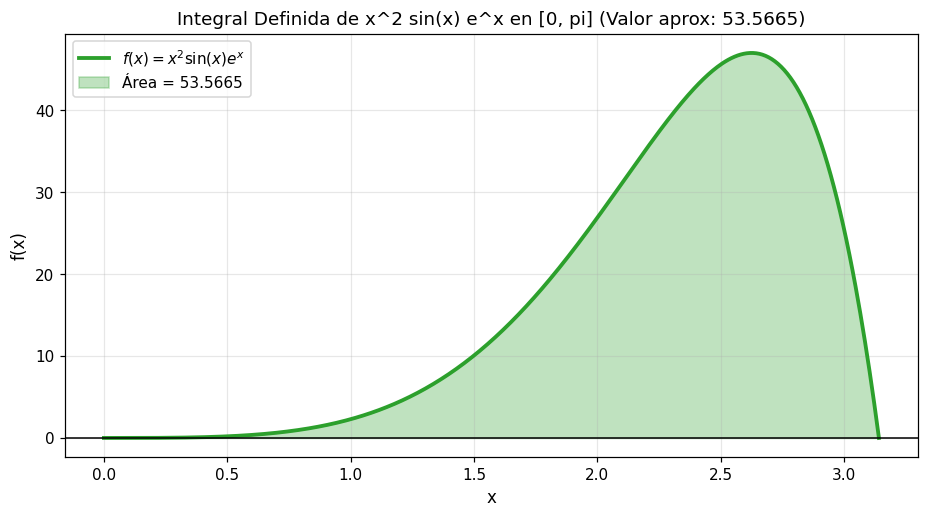

In [9]:
from sympy import Symbol, integrate, sin, exp, pi, N
import numpy as np
import matplotlib.pyplot as plt

x = Symbol('x')

# Definir función f(x) = x^2 * sin(x) * exp(x)
f = x**2 * sin(x) * exp(x)

print("="*70)
print("MY OWN EXAMPLE 10: INTEGRACIÓN SIMBÓLICA Y NUMÉRICA CON SYMPY")
print("="*70)
print("Función f(x):")
print(f)

# 1. Integral Indefinida
integral_indef = integrate(f, x)
print("\n1. Integral Indefinida simbólica ∫ x^2 sin(x) e^x dx:")
print(integral_indef)

# 2. Integral Definida en [0, pi]
integral_def = integrate(f, (x, 0, pi))
print("\n2. Integral Definida exacta ∫_0^π x^2 sin(x) e^x dx:")
print(integral_def)

# 3. Evaluación numérica con 30 dígitos
integral_num = N(integral_def, 30)
print("\n3. Valor numérico de alta precisión (30 dígitos):")
print(integral_num)

# Gráfica del área bajo la curva
x_arr = np.linspace(0, float(pi), 500)
f_numpy = x_arr**2 * np.sin(x_arr) * np.exp(x_arr)

plt.figure(figsize=(10, 5))
plt.plot(x_arr, f_numpy, color='#2ca02c', lw=2.5, label=r'$f(x) = x^2 \sin(x) e^x$')
plt.fill_between(x_arr, f_numpy, color='#2ca02c', alpha=0.3, label=f'Área = {float(integral_num):.4f}')
plt.axhline(0, color='black', lw=1)

plt.title('Integral Definida de x^2 sin(x) e^x en [0, pi] (Valor aprox: 53.5665)', fontsize=12)
plt.xlabel('x', fontsize=11)
plt.ylabel('f(x)', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left', frameon=True)
plt.show()
